# Customer Lifetime Value & Retention - Online Retail II

**Business question:** which customers will be worth the most over the next six months, and where
should a retention team spend its effort?

This notebook walks through the pipeline using the same functions as the scripts in `src/`.
Run `python run_all.py` once first (it creates the cleaned data in `data/`).

In [1]:
import sys, sqlite3, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from common import OUTPUTS, POWERBI, DOCS, SQLITE_DB

## 1. Cleaning
Rules: drop missing Customer ID, drop cancellation invoices (start with `C`), keep Quantity > 0 and Price > 0. Exact duplicates are **detected but kept**.

In [2]:
pd.read_csv(POWERBI / "fact_cleaning_log.csv")

,step,rows_before,rows_after,rows_removed,rule
0,raw_rows,1067371,1067371,0,Two workbook sheets concatenated
1,type_coercion,1067371,1067371,0,Parsed dates/numerics; trimmed text
2,valid_invoice_date,1067371,1067371,0,Removed unparseable InvoiceDate
3,known_customer,1067371,824364,243007,Removed rows without Customer ID
4,exclude_cancellations,824364,805620,18744,Removed invoices with Invoice beginning C
5,positive_sales,805620,805549,71,Kept Quantity > 0 and Price > 0
6,duplicate_handling,805549,805549,0,Exact duplicates detected=26124; retained to a...


In [3]:
pd.read_csv(OUTPUTS / "clean_summary.csv")

,Metric,Value
0,Raw rows,1067371
1,Usable transaction rows,805549
2,Usable customers,5878
3,Usable invoices,36969
4,Exact duplicates detected and retained,26124
5,Historical revenue,17743429.178000003
6,Min InvoiceDate,2009-12-01 07:45:00
7,Max InvoiceDate,2011-12-09 12:50:00
8,RFM snapshot date,2011-12-09


## 2. RFM
One invoice = one purchase. Scores are quintiles of `rank(method="first")` on a table sorted by Customer ID (deterministic ties). R is reversed so 5 = most recent.

In [4]:
from rfm_cohort import load_clean, invoice_level, build_rfm
df = load_clean()
inv = invoice_level(df)
snapshot = df["InvoiceDate"].max().normalize()
cust = build_rfm(inv, snapshot)
print("snapshot:", snapshot.date(), "| customers:", len(cust))
cust[["Customer ID","RecencyDays","Frequency","Monetary","R_Score","F_Score","M_Score","RFM_Segment"]].head()

snapshot: 2011-12-09 | customers: 5878


,Customer ID,RecencyDays,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment
0,12346,325,12,77556.46,2,5,5,At-risk loyal
1,12347,2,8,5633.32,5,4,5,Champions
2,12348,75,5,2019.40,3,4,4,Core customers
3,12349,18,4,4428.69,5,3,5,Core customers
4,12350,310,1,334.40,2,1,2,Hibernating


In [5]:
cust.groupby("RFM_Segment").agg(customers=("Customer ID","size"), revenue=("Monetary","sum")).sort_values("revenue", ascending=False)

,customers,revenue
RFM_Segment,,
Champions,1292,1.209858e+07
Core customers,1794,2.947517e+06
At-risk loyal,824,1.634295e+06
Hibernating,1527,6.686467e+05
New / promising,441,3.943932e+05


## 3. Cohort retention
Cohort = month of first purchase. Retention = active customers in month N / cohort size.

In [6]:
pd.read_csv(OUTPUTS / "retention_summary.csv")

,Metric,Value,CohortsObserved
0,Average month+1 retention,0.211656,24
1,Average month+3 retention,0.216158,22
2,Average month+6 retention,0.178213,19


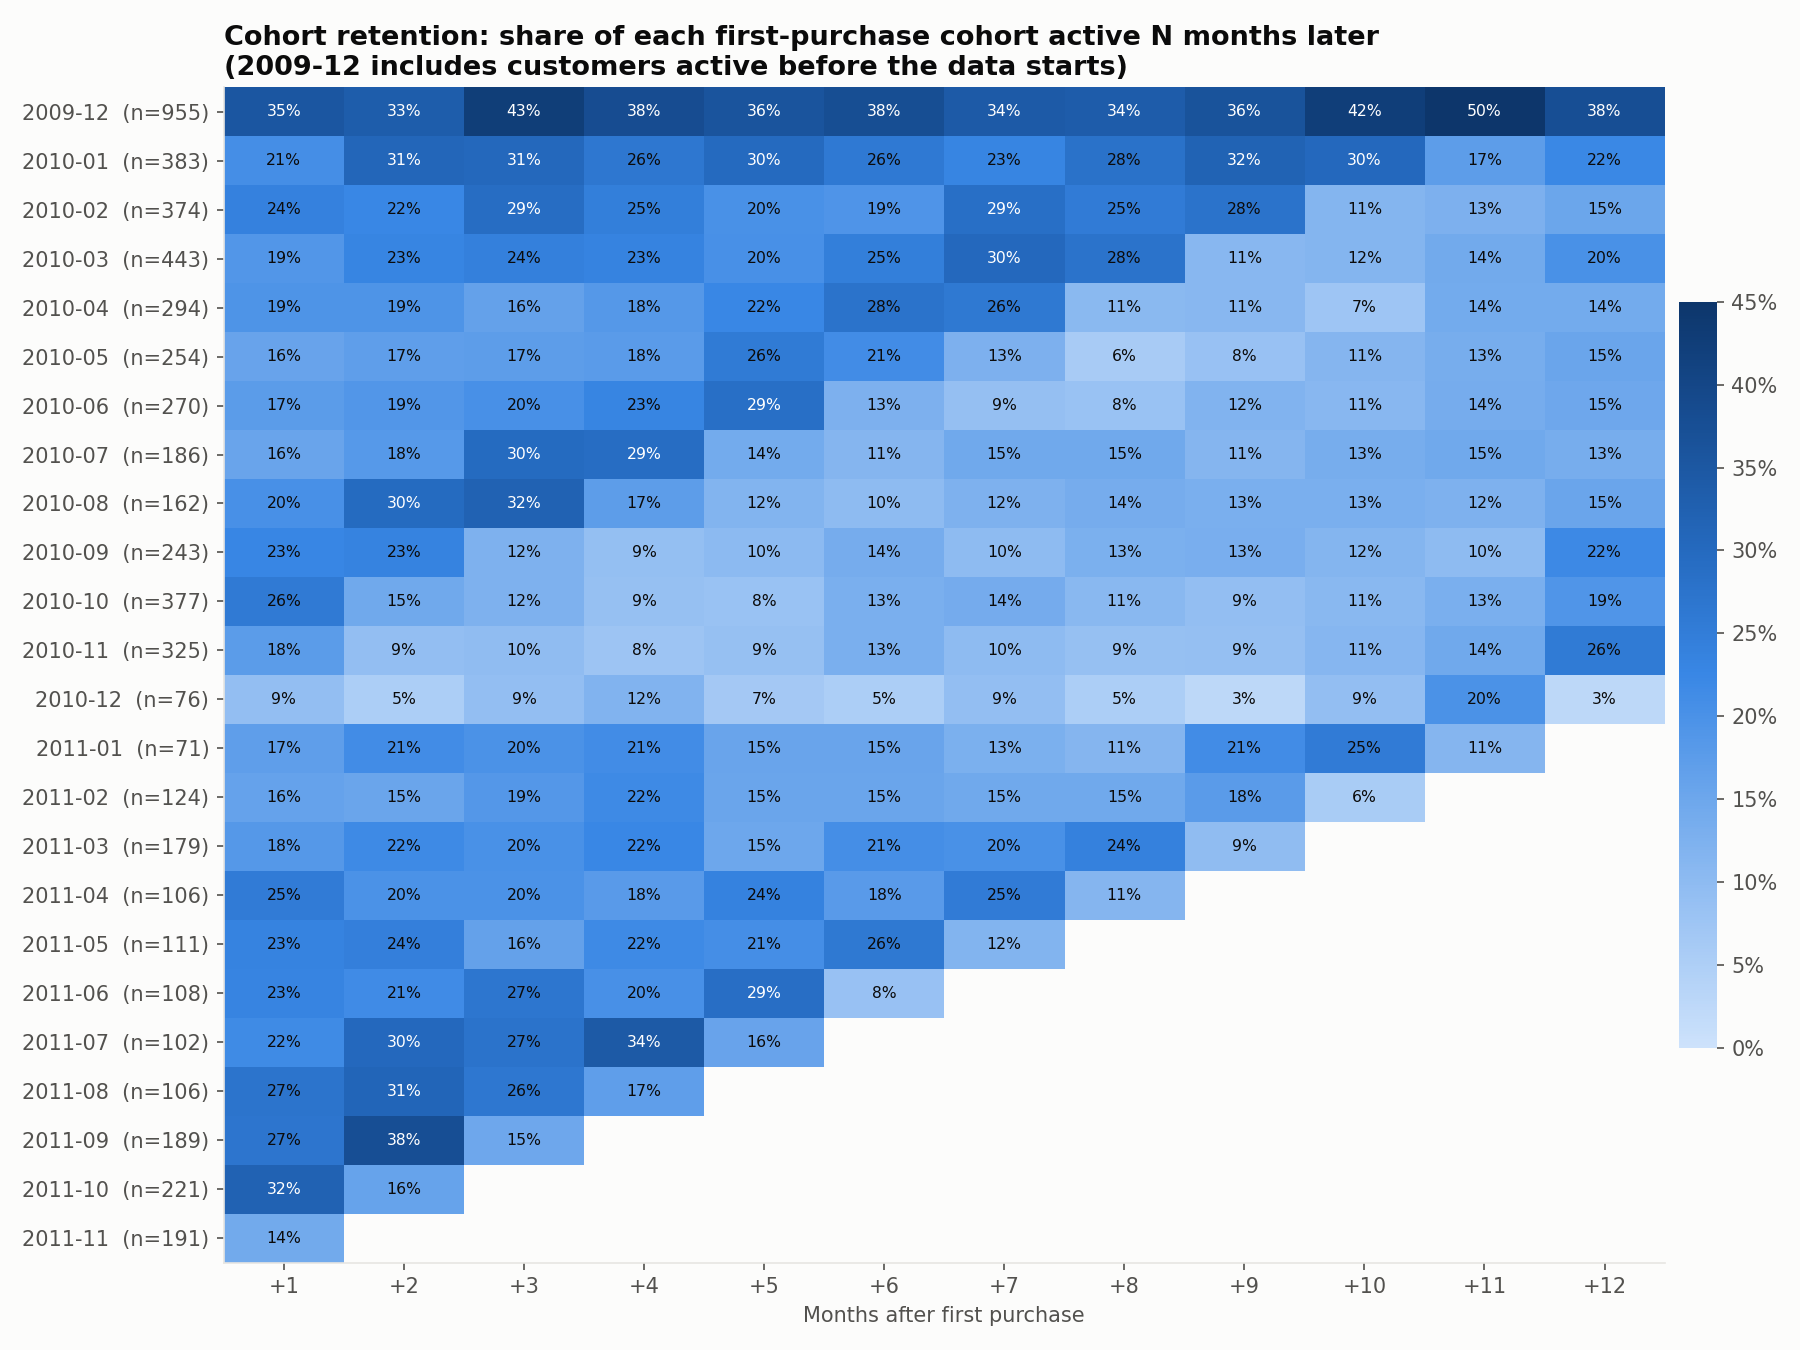

In [7]:
display(Image(str(DOCS / "cohort_retention_heatmap.png"), width=800))

## 4. BG/NBD + Gamma-Gamma -> 26-week predicted CLV
* **BG/NBD**: how many purchases a customer will make, and the probability they are still "alive".
* **Gamma-Gamma**: how much they spend per order (repeat customers only).
* **CLV** = expected purchases x expected order value, discounted 1 % per week, over 26 weeks.

In [8]:
from models import run_models
c, bgf, ggf = run_models(cust, snapshot)
print("BG/NBD params:", bgf.params_.round(4).to_dict())
print("Gamma-Gamma params:", ggf.params_.round(4).to_dict())
clv = c["PredictedCLV_26w"].dropna()
print(f"modelled customers {len(clv):,} | total {clv.sum():,.2f} | mean {clv.mean():,.2f} | median {clv.median():,.2f}")

BG/NBD params: {'r': 0.6131, 'alpha': 6.9115, 'a': 0.0972, 'b': 1.3346}
Gamma-Gamma params: {'p': 12.476, 'q': 0.9409, 'v': 12.3093}
modelled customers 4,255 | total 17,104,456.67 | mean 4,019.85 | median 1,511.36


### Worked example - one real customer (12347)

In [9]:
c.loc[c["Customer ID"] == 12347, ["Customer ID","Frequency","Monetary","RecencyDays","frequency","recency","T",
   "PredictedPurchases_26w","ProbabilityAlive","AverageOrderValue","ExpectedAverageValue","PredictedCLV_26w","CustomerSegment"]].T

,1
Customer ID,12347
Frequency,8
Monetary,5633.32
RecencyDays,2
frequency,7
recency,57.428571
T,57.714286
PredictedPurchases_26w,2.968581
ProbabilityAlive,0.986476
AverageOrderValue,704.165


## 5. Segments

In [10]:
seg = pd.read_csv(POWERBI / "fact_segment_summary.csv")
seg

,RFM_Segment,CLV_Segment,Customers,HistoricalRevenue,PredictedCLV26w,MedianPredictedCLV26w,MedianRecencyDays,MedianFrequency
0,Champions,High CLV,785,1.085419e+07,1.089646e+07,6969.359241,10.0,15.0
1,Core customers,High CLV,235,1.245905e+06,1.661738e+06,5158.419334,66.0,6.0
2,Champions,Mid-high CLV,438,1.140274e+06,1.120951e+06,2552.668711,22.0,9.0
3,Core customers,Mid-high CLV,488,9.221824e+05,1.112256e+06,2150.706695,71.0,5.0
4,Core customers,Mid-low CLV,609,5.893842e+05,6.174333e+05,996.186590,65.0,4.0
5,New / promising,High CLV,33,2.136656e+05,5.203020e+05,5377.238264,9.0,2.0
6,At-risk loyal,Mid-low CLV,254,4.147962e+05,2.271310e+05,843.759369,296.5,4.0
7,At-risk loyal,Mid-high CLV,70,2.387907e+05,1.536933e+05,2124.438003,239.5,6.0
8,New / promising,Mid-high CLV,57,4.024561e+04,1.392738e+05,2384.926181,22.0,2.0
9,At-risk loyal,Low CLV,490,7.897488e+05,1.305704e+05,270.084320,401.0,3.0


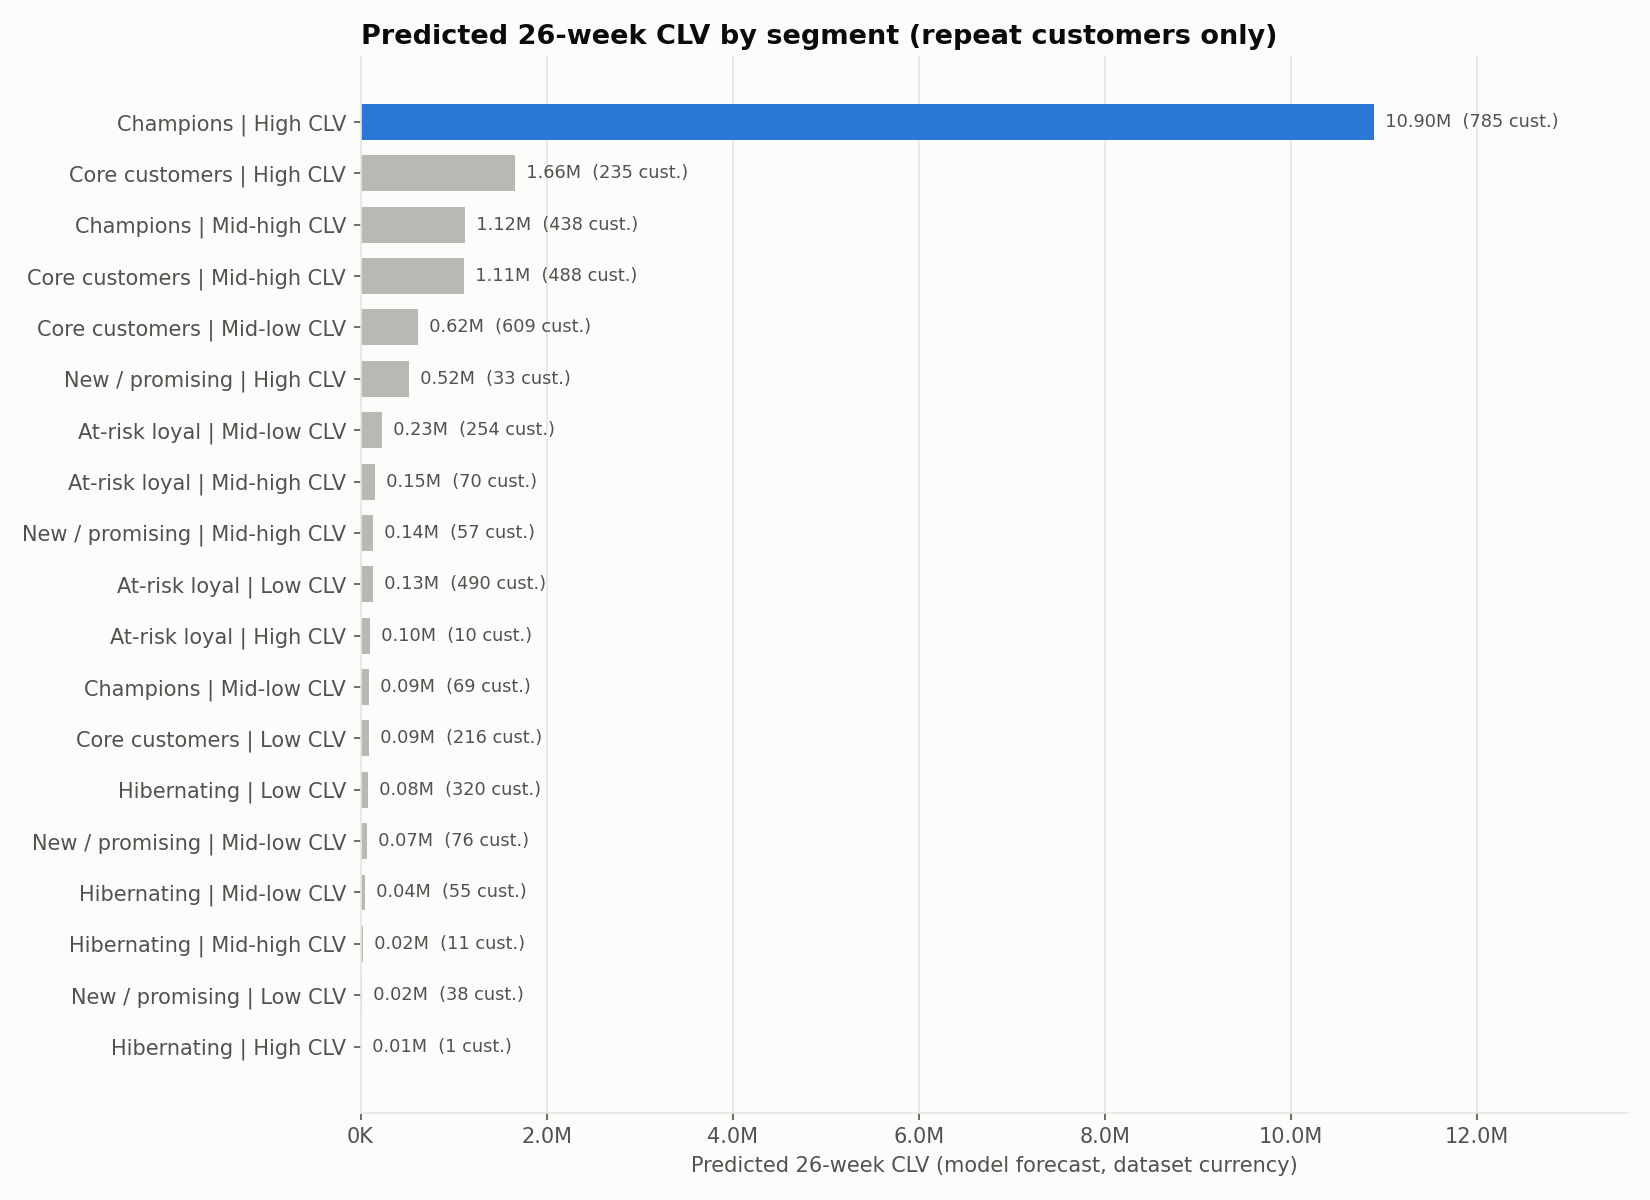

In [11]:
display(Image(str(DOCS / "segment_predicted_clv.png"), width=800))

## 6. Model sanity checks
Fit on the first half of the data, predict the second half, compare with what actually happened.

In [12]:
pd.read_csv(OUTPUTS / "calibration_holdout.csv")

,calibration_repeat_purchases,customers,avg_actual,avg_predicted,total_actual,total_predicted,error_pct
0,0,1429,0.886,2.007,1266.0,2868.680,126.594
1,1,820,1.538,3.038,1261.0,2491.157,97.554
2,2,511,2.090,3.905,1068.0,1995.231,86.819
3,3-4,625,3.328,5.213,2080.0,3258.386,56.653
4,5-9,589,5.338,7.631,3144.0,4494.386,42.951
5,10+,317,16.744,19.748,5308.0,6260.209,17.939
6,ALL,4291,3.292,4.980,14127.0,21368.049,51.257


In [13]:
pd.read_csv(OUTPUTS / "sanity_checks.csv")

,Check,Value
0,BG/NBD r,0.6130830402058234
1,BG/NBD alpha,6.911461899541706
2,BG/NBD a,0.0972207078943579
3,BG/NBD b,1.3346098181707031
4,Gamma-Gamma p,12.47598203499337
5,Gamma-Gamma q,0.9408641302327028
6,Gamma-Gamma v,12.309264835027305
7,Calibration split date,2010-12-05
8,Holdout weeks,52.71
9,Calibration-fit BG/NBD r,0.775279


**Reading it:** predicted and actual purchases are well correlated (the model ranks customers well) but the model over-predicts volume, most for low-frequency customers. Treat CLV as a ranking tool and an optimistic estimate.

## 7. SQL layer
The same RFM logic in SQLite (window functions). Example: top 10 customers with `RANK()`.

In [14]:
con = sqlite3.connect(SQLITE_DB)
pd.read_sql_query(open("sql/clv_analysis.sql").read().split("-- name: top10_customers")[1].split("-- name:")[0], con)

,customer_id,revenue,orders,revenue_rank,share_of_revenue_pct
0,18102,608821.65,145,1,3.43
1,14646,528602.52,151,2,2.98
2,14156,313946.37,156,3,1.77
3,14911,295972.63,398,4,1.67
4,17450,246973.09,51,5,1.39
5,13694,196482.81,143,6,1.11
6,17511,175603.55,60,7,0.99
7,16446,168472.50,2,8,0.95
8,16684,147142.77,55,9,0.83
9,12415,144458.37,28,10,0.81


In [15]:
pd.read_csv(OUTPUTS / "sql_parity_check.csv")

,check,result,detail
0,customer count,PASS,"pandas 5878, sql 5878"
1,RecencyDays equal,PASS,0 customers differ
2,Frequency equal,PASS,0 customers differ
3,R_Score equal,PASS,0 customers differ
4,F_Score equal,PASS,0 customers differ
5,M_Score equal,PASS,0 customers differ
6,Monetary equal (2dp),PASS,max abs diff 0.0000
7,RFM_Segment equal,PASS,0 customers differ
8,(info) plain NTILE(5) vs pandas R_Score,INFO,3 customers would differ if NTILE(5) were used
9,(info) plain NTILE(5) vs pandas F_Score,INFO,3 customers would differ if NTILE(5) were used


## 8. Verification

In [16]:
import subprocess
print(subprocess.run([sys.executable, "-W", "ignore", "verify.py"], capture_output=True, text=True).stdout[-900:])

ical to reference                            rebuilt                yes  target                yes  (exact)
PASS  Customer R_Score identical to reference (5,878 rows)       rebuilt                  0  target                  0  (exact)
PASS  Customer F_Score identical to reference (5,878 rows)       rebuilt                  0  target                  0  (exact)
PASS  Customer M_Score identical to reference (5,878 rows)       rebuilt                  0  target                  0  (exact)
PASS  Customer RFM_Segment identical to reference (5,878 rows)   rebuilt                  0  target                  0  (exact)
PASS  Customer CLV_Segment identical to reference (5,878 rows)   rebuilt                  0  target                  0  (exact)
PASS  SQL vs pandas parity checks (12)                           rebuilt                yes  target                yes  (exact)

65 of 65 checks passed

